<a href="https://colab.research.google.com/github/AbhinandLaji/Ai-Ml-lab/blob/main/AI_ML_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

# 1. Set seed for reproducibility
np.random.seed(42)

# 2. Define the number of students
n_samples = 2000

# 3. Generate random features (Independent Variables)
study_time = np.random.uniform(0, 10, n_samples)
previous_grade = np.random.uniform(50, 100, n_samples)
attendance = np.random.uniform(50, 100, n_samples)
sleep = np.random.uniform(4, 10, n_samples)

internet_access = np.random.choice([0, 1], n_samples, p=[0.1, 0.9])
extracurricular = np.random.choice([0, 1], n_samples, p=[0.4, 0.6])
part_time_job = np.random.choice([0, 1], n_samples, p=[0.7, 0.3])
gender_male = np.random.choice([0, 1], n_samples, p=[0.5, 0.5])

total_productive_hours = study_time + (extracurricular * np.random.uniform(1, 3, n_samples))

# 4. Define the exact underlying linear relationship
base_score = 15

true_score = (
    base_score +
    (5.5 * study_time) +
    (0.3 * previous_grade) +
    (0.15 * attendance) +
    (1.2 * sleep) +
    (6.0 * internet_access) +
    (2.0 * extracurricular) -
    (4.5 * part_time_job) -
    (0.2 * gender_male)
)

# 5. CREATE OUTLIERS to drop accuracy to ~90%+
# Step A: Give everyone a very small baseline noise (Standard Deviation = 1.0)
noise = np.random.normal(0, 1.0, n_samples)

# Step B: Pick 5% of the students at random to be outliers (100 students)
num_outliers = int(0.05 * n_samples)
outlier_indices = np.random.choice(n_samples, num_outliers, replace=False)

# Step C: Inject heavy noise (Standard Deviation = 15.0) just to those 100 students
noise[outlier_indices] += np.random.normal(0, 15.0, num_outliers)

# Combine the true score with our new modified noise
final_score = true_score + noise

# 6. Combine everything into a Pandas DataFrame
df = pd.DataFrame({
    'Study_Time': study_time,
    'Previous_Grade': previous_grade,
    'Attendance': attendance,
    'Sleep': sleep,
    'Internet_Access': internet_access,
    'Extracurricular': extracurricular,
    'Part_Time_Job': part_time_job,
    'Gender_Male': gender_male,
    'Total_Productive_Hours': total_productive_hours,
    'Score': final_score
})

# 7. Save to CSV
df.to_csv("outlier_student_data.csv", index=False)
print("Dataset successfully generated and saved as 'outlier_student_data.csv'!")

Dataset successfully generated and saved as 'outlier_student_data.csv'!


📊 Model Performance:
R-squared (R²): 0.9334 (Closer to 1.0 is better)
Mean Squared Error: 20.50
------------------------------


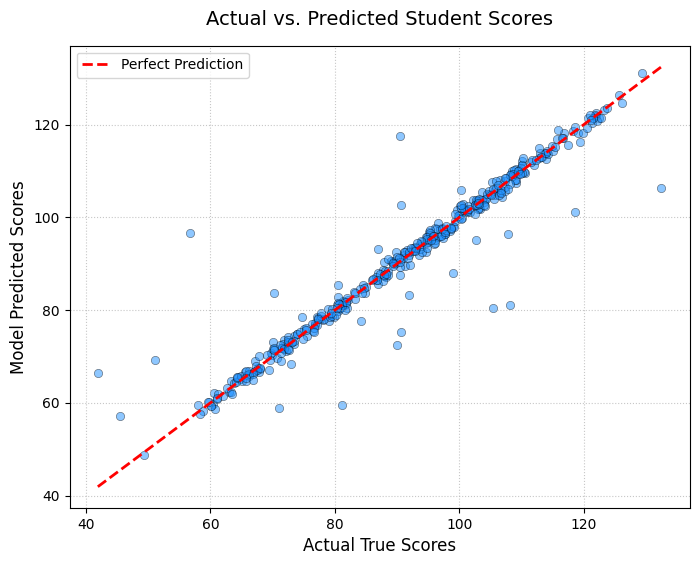

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Make sure plots render inline in notebooks
%matplotlib inline

# ---------------------------------------------------------
# 1. LOAD THE DATA
# ---------------------------------------------------------
# Assuming you ran the previous code and saved the CSV
df = pd.read_csv("outlier_student_data.csv")

# Separate the Features (Independent Variables) from the Target (Dependent Variable)
X = df.drop(columns=['Score'])
y = df['Score']

# ---------------------------------------------------------
# 2. TRAIN THE MODEL
# ---------------------------------------------------------
# Split the data: 80% for training the model, 20% for testing its accuracy
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train (fit) the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions using the unseen test data
y_pred = model.predict(X_test)

# Check model accuracy
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f"📊 Model Performance:")
print(f"R-squared (R²): {r2:.4f} (Closer to 1.0 is better)")
print(f"Mean Squared Error: {mse:.2f}")
print("-" * 30)

# ---------------------------------------------------------
# 3. VISUALIZE THE RESULTS
# ---------------------------------------------------------

# --- Graph 1: Actual vs. Predicted Scores ---
plt.figure(figsize=(8, 6))

# Plot the test predictions
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, color='dodgerblue', edgecolor='k')

# Draw the perfect prediction line (y = x)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.title('Actual vs. Predicted Student Scores', fontsize=14, pad=15)
plt.xlabel('Actual True Scores', fontsize=12)
plt.ylabel('Model Predicted Scores', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

# Display Graph 1
plt.show()

